# Title

## Introduction
SINTEF is an independent research organization headquartered in Trondheim that researches hydropower among other things. The Tokke-Vinje watercourse is a system comprising 14 generating units in 9 power plants connected to 17 reservoirs by a web of rivers in Norway's Tokke and Vinje municipalities. SINTEF published a dataset containing the Unit Commitment decisions of hydropower plants from 2015 to 2026, along with other relevant data that was used in making these UC decisions. (https://snl.no/SINTEF , https://data.sintef.no/product/dp-df280e4c-09c8-49a4-aef9-5f9f1133c500 ) The aim of this project is to use machine learning to predict the UC decisions from the input data, and to speed up the decision process relative to using mathematical optimization methods. The model is created using the data from 2015-01-01 to 2023-01-01 and tested using the data from 2023-01-01 to 2024-12-25. The data was examined first through Exploratory Data Analysis to inform model decisions and help guide feature engineering. Through feature engineering, additional relations between features or patterns and combinations, and their correlation to the output decisions were explored. This allowed for the creation of a linear model that was able to capture deeper patterns and relations, that were not easily benefited from by only using the raw input data. After that, multiple types of models were considered and tested, before finally choosing and optimizing one through hyperparameter tuning. Finally, the effectiveness of the model and its features were interpreted and evaluated.

## Exploratory Data Analysis
EDA was performed on both the data in the core dataset as well as the data in the extended dataset to gain an understanding and an overview of the problem as well as the relevant variables. Each variable was examined separately first and plotted as a function of time to visualize the data and possibly reveal anomalies, patterns or trends to research further. This notebook contains a small selection of relevant plots to illustrate certain points discussed in the text. Through the EDA, the data was determined not to be majorly corrupted nor missing significant amounts of entries, and as a result no further cleanup was performed.

Prices were found to be quite volatile, and large spikes in later years were also discovered. These findings are in accordance with the factual spikes in energy prices recorded at that time as a result of geopolitical events, and lower than average precipitation in southern Norway. (https://www.ssb.no/en/energi-og-industri/energi/statistikk/elektrisitetspriser/article-for-electricity-prices/record-high-electricity-price-in-2022--curbed-by-electricity-support-for-households , https://www.sciencedirect.com/science/article/pii/S2666955223000357) Trends and seasonalities were also checked, resulting in the same peeks and suggesting the use of normalized and ranked features for training the model.

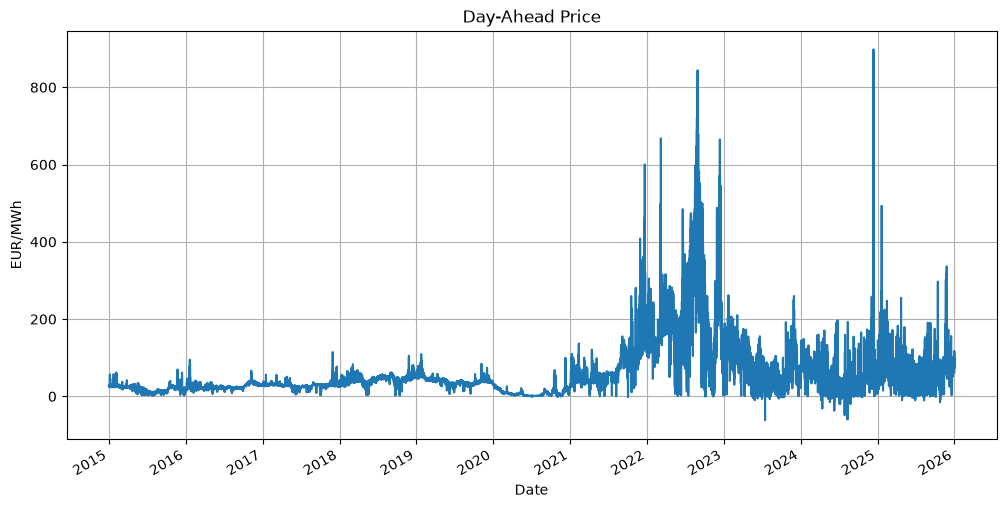

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import numpy as np
df = pd.read_csv("sintef_project/data/kernel/Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"], index_col="date")
price = df["Day-ahead price (EUR/MWh)"]
ax = price.plot(figsize=(12, 6))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Day-Ahead Price")
ax.set_ylabel("EUR/MWh")
ax.set_xlabel("Date")
ax.grid(True)
plt.show()

Evidence of this lower than average precipitation was also found in the inflow data (2022 had a total inflow of approx. $29*10^{8} m^{3}$ while the average over 10 years was approx. $36*10^{8} m^{3}$), which is assumed to mainly reflect rainfall. The inflow data was examined per power plant and a visual inspection of the plotted data seems to suggest yearly patterns shared by most reservoirs, although less pronounced in some, even though the average difference in absolute inflow between the minimum (Vatjern) and maximum (Songavatn) reservoirs is about 2 orders of magnitude. These patterns are likely a result of seasonal differences in precipitation. (https://www.meteoblue.com/en/weather/historyclimate/weatherarchive/norway_united-states_4973840?fcstlength=1y&year=2026&month=10) The figure below only plots data from 2015 onwards to more sharply show the patterns. It will still be useful to incorporate earlier data into the model through lagged or ranked features. The plots also include optional minimum flow requirements, as not all reservoirs have them. The inflow often greatly exceeds these requirements meaning that provisioning extra water storage will likely not be necessary to meet them, but still dips below them occasionally, suggesting the requirements might still be valuable to take into account. Lastly, a correlation matrix between the reservoirs with respect to their inflows was computed, and the inflows of some reservoirs were found to be perfectly correlated, implying they are directly up/downstream from each other and share the same micro-climate basin, which is confirmed by the topology.

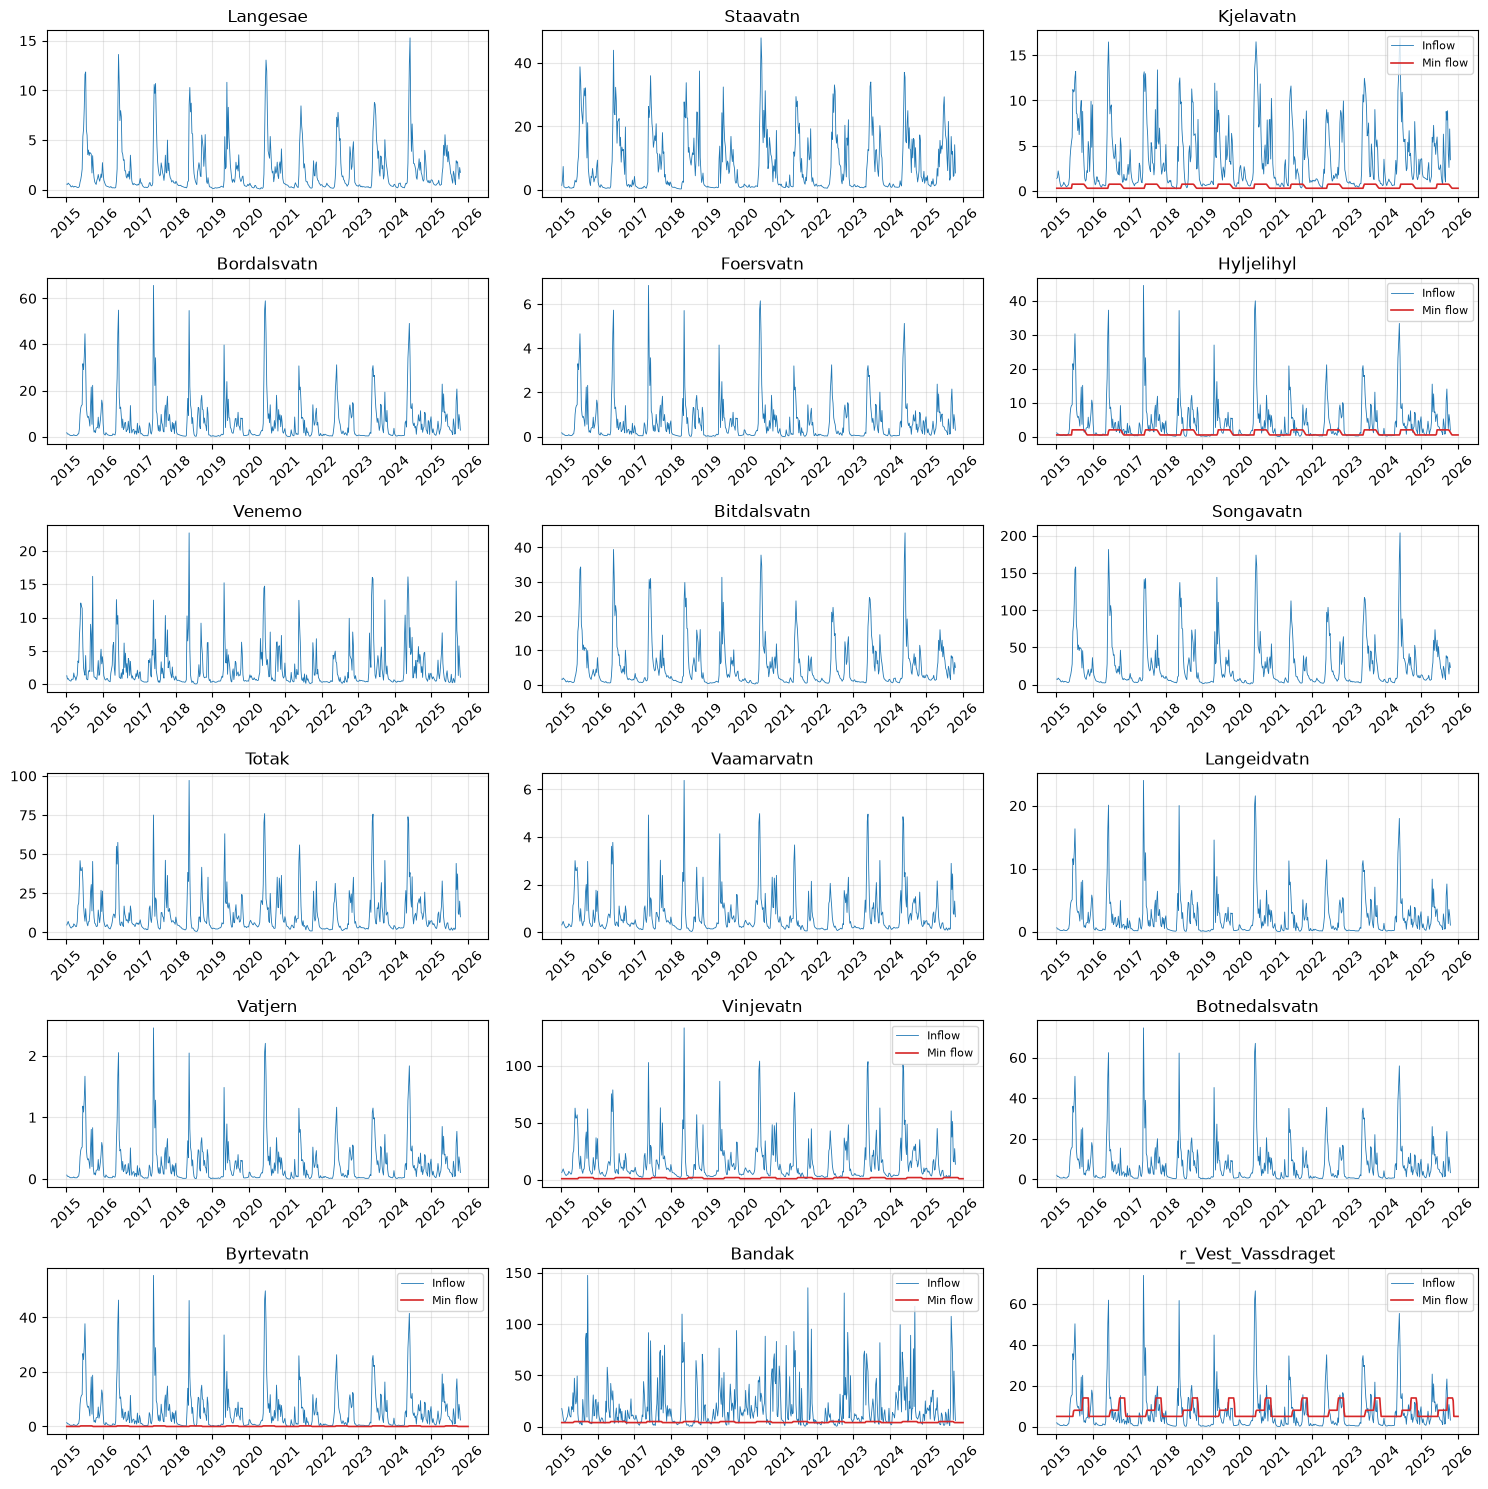

In [4]:
inflow = pd.read_csv("sintef_project/data/kernel/Historical_inflow_1958_2025.csv")
inflow["date"] = pd.to_datetime(inflow["date"])
inflow = inflow[inflow["date"] >= "2015-01-01"]
min_flow = pd.read_csv("sintef_project/data/extended/Constraint_min_flow.csv")
min_flow["date"] = pd.to_datetime(min_flow["date"])
inflow_r = inflow.set_index("date").resample("W").mean()
min_r = min_flow.set_index("date").resample("W").mean()
units = list(inflow_r.columns)
min_map = {c[2:] if c.startswith("b_") else c: c for c in min_r.columns}
ncols = 3
nrows = int(np.ceil(len(units) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 2.5 * nrows), sharex=True)
axes = axes.flatten()
for ax, unit in zip(axes, units):
    ax.plot(inflow_r.index, inflow_r[unit], lw=0.6, label="Inflow")
    if unit in min_map:
        ax.plot(min_r.index, min_r[min_map[unit]], lw=1.2, color="tab:red", label="Min flow")
        ax.legend(loc="upper right", fontsize=8)
    ax.set_title(unit)
    ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(axis="x", labelbottom=True, labelrotation=45)
for ax in axes[len(units):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

The volume data was also considered per power plant and visualized as such. These plots also reveal clear patterns, although there are many more variations and deviations than with the inflow data. Most reservoirs seem to again indicate some seasonality with the exception of Vinjevatn and Bandak only showing weak seasonality, which is true to reality as well. (https://sildre.nve.no/station/16.6.0?16.6.0.1000_period=custom&16.6.0.1000_res=0&16.6.0.1000_to=2026-10-30&16.6.0.1000_from=2014-10-30&16.6.0.1000_decimals=3) The storage volume of two reservoirs, Hyljelihyl and Vatjern, also remains unchanged throughout the entire dataset, which seems to be correct (https://vannkart.no/en/stasjon/16.148.0) and implies that no water is stored at these reservoirs, everything flowing in also directly flows back out. Three reservoirs also have minimum volume requirements, which were added to their respective plots. These requirements are also clearly seasonal, and align more closesly with the actuale storage volumes, suggesting a significant effect on the storage volume and as a result the water management of those reservoirs as a whole. These minimum requirements are the result of a ploy to mitigate the impact of the hydropower plants on the local ecology. (https://www.regjeringen.no/no/aktuelt/regjeringen-vedtar-miljoforbedringer-for-tokke-vinje-reguleringen/id2919450/ ) A correlation matrix was again computed and no perfect correlations were present this time, although some strong correlations were present. This can be partly explained by geographical proximity and up-/downstream connectedness but might also imply that these reservoirs are managed using a common shadow price (and as a result turned on/off at mostly the same times).

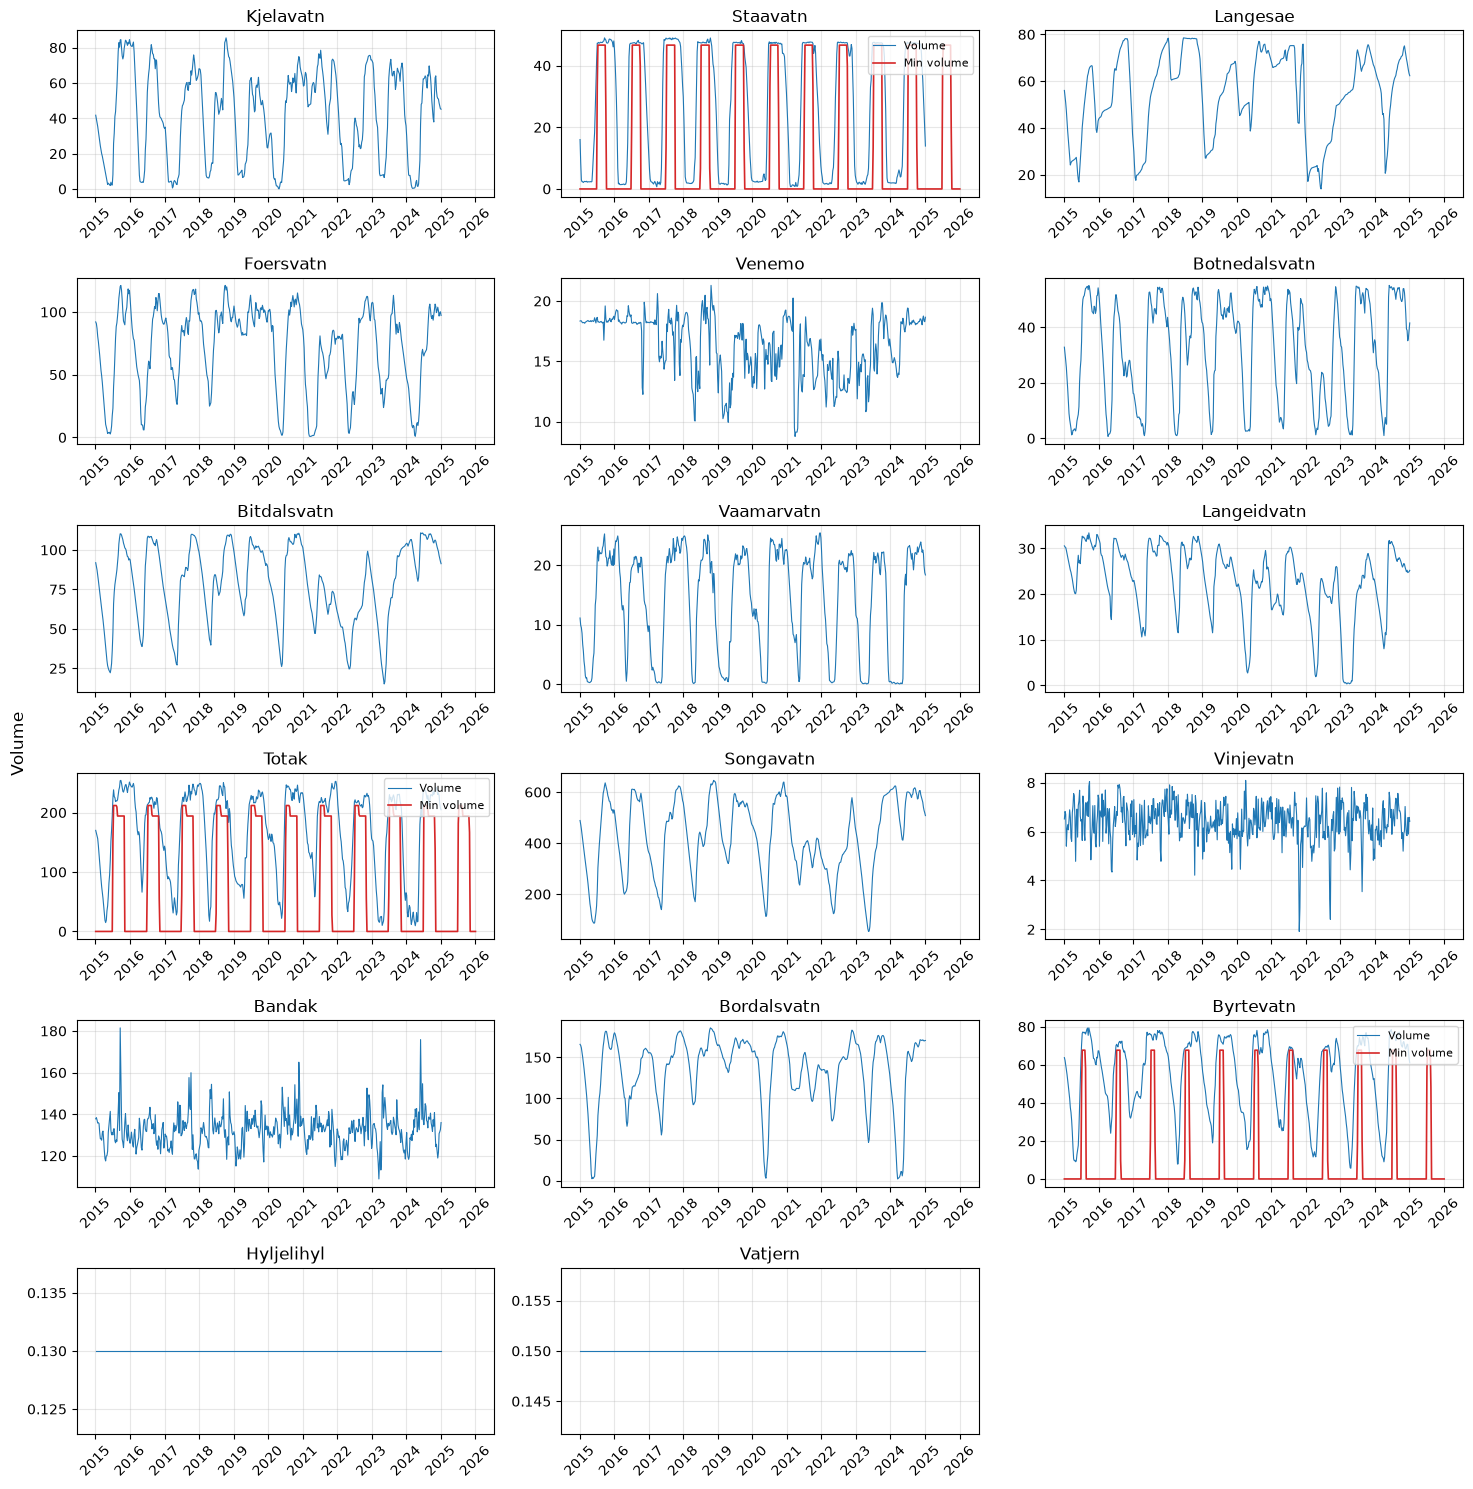

In [5]:
volume = pd.read_csv("sintef_project/data/kernel/Historical_volume_2015_2024.csv")
volume["date"] = pd.to_datetime(volume["date"])
min_vol = pd.read_csv("sintef_project/data/extended/Constraint_min_volume.csv")
min_vol["date"] = pd.to_datetime(min_vol["date"])
volume_r = volume.set_index("date").resample("W").mean()
min_r = min_vol.set_index("date").resample("W").mean()
units = list(volume_r.columns)
ncols = 3
nrows = int(np.ceil(len(units) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 2.5 * nrows), sharex=True)
axes = axes.flatten()
for ax, unit in zip(axes, units):
    ax.plot(volume_r.index, volume_r[unit], lw=0.8, label="Volume")
    if unit in min_r.columns:
        ax.plot(min_r.index, min_r[unit], lw=1.2, color="tab:red", label="Min volume")
        ax.legend(loc="upper right", fontsize=8)
    ax.set_title(unit)
    ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(axis="x", labelbottom=True, labelrotation=45)
for ax in axes[len(units):]:
    ax.set_visible(False)
fig.supylabel("Volume")
fig.tight_layout()
plt.show()

The synthetic water value is important to balance supply and demand of water. If producers set the water value too low, consumption increases, which can lead to empty reservoirs before the dry season is over. This value depends on how long it is possible to store the water, and is calculated using statistics, forecasts, and models to make advanced mathematical calculations on production and consumption. (https://www.nve.no/norwegian-energy-regulatory-authority/the-norwegian-energy-regulatory-authority/water-values-how-do-we-ensure-that-we-utilize-hydropower-in-the-best-possible-way/ ) When plotted, it shows a very similar picture as the day-ahead price: it seems just as volatile and shows almost identical spikes in 2022. The average correlation between the price and water value per unit is 0.88, which makes a lot of sense intuitively as the water value is directly linked to the electricity prices. The water value drops down to just above zero at certain points, which probably indicates an excess of water in those reservoirs. Each reservoir spend about 10% of the time in such a state of excess. The hypothesis of common shadow prices put forward in the previous paragraph also seems to be supported by the fact that several groups of plots have almost identical shapes.

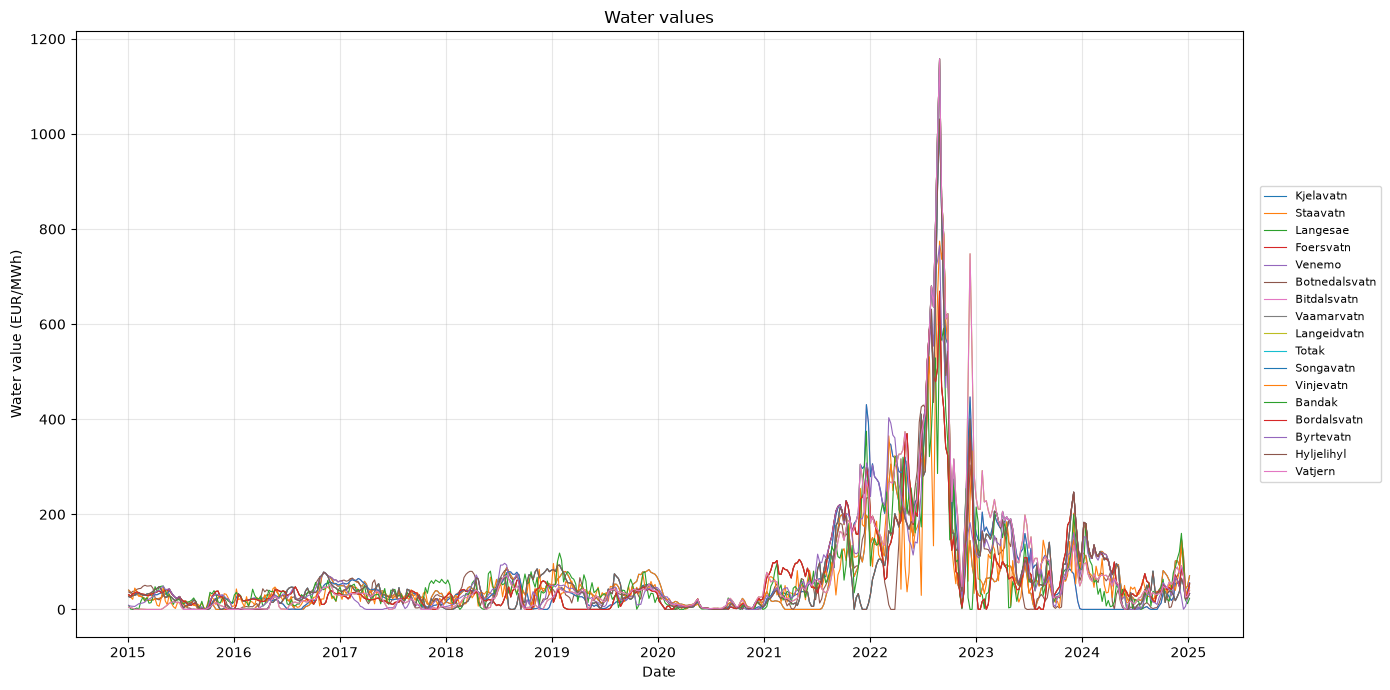

In [6]:
value = pd.read_csv("sintef_project/data/kernel/Synthetic_water_value_2015_2024.csv")
value["date"] = pd.to_datetime(value["date"])
value = value.set_index("date")
value_r = value.resample("W").mean()
fig, ax = plt.subplots(figsize=(14, 7))
for col in value_r.columns:
    ax.plot(value_r.index, value_r[col], lw=0.8, label=col)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Water values")
ax.set_xlabel("Date")
ax.set_ylabel("Water value (EUR/MWh)")
ax.grid(alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8, ncol=1)
fig.tight_layout()
plt.show()

The unit commitment decisions are stored in cases of 168-hour horizons for each of the 14 generating units. For a profit-maximizing producer, generators are expected to be turned on when prices are high. Contrary to this expectation, the median day-ahead price is lower in hours where most generators are committed than in hours where they are off. This holds for 12 of the 14 units, with differences ranging from about -1 to -8 EUR/MWh (largest for Haukeli_G1, Lio_G1, Tokke_G1 and Tokke_G3). The median price when on is remarkably similar across units (about 30 EUR/MWh), while the median price when off varies more. This suggests that commitment is not driven by the spot price alone. Possible explanations are that the decisions come from an optimization with a 168-hour horizon, where the water value, reservoir levels, inflow and minimum flow constraints can outweigh hourly prices. Since water values are partly set by expected future prices, plants may run in moderately priced hours when reservoirs are full or inflow is high, and stay off in high-priced hours if the water is judged more valuable later. Seasonal effects may also play a role, since prices and operation both vary through the year. Overall, price alone is a weak predictor of unit commitment, which motivates informed feature extraction.

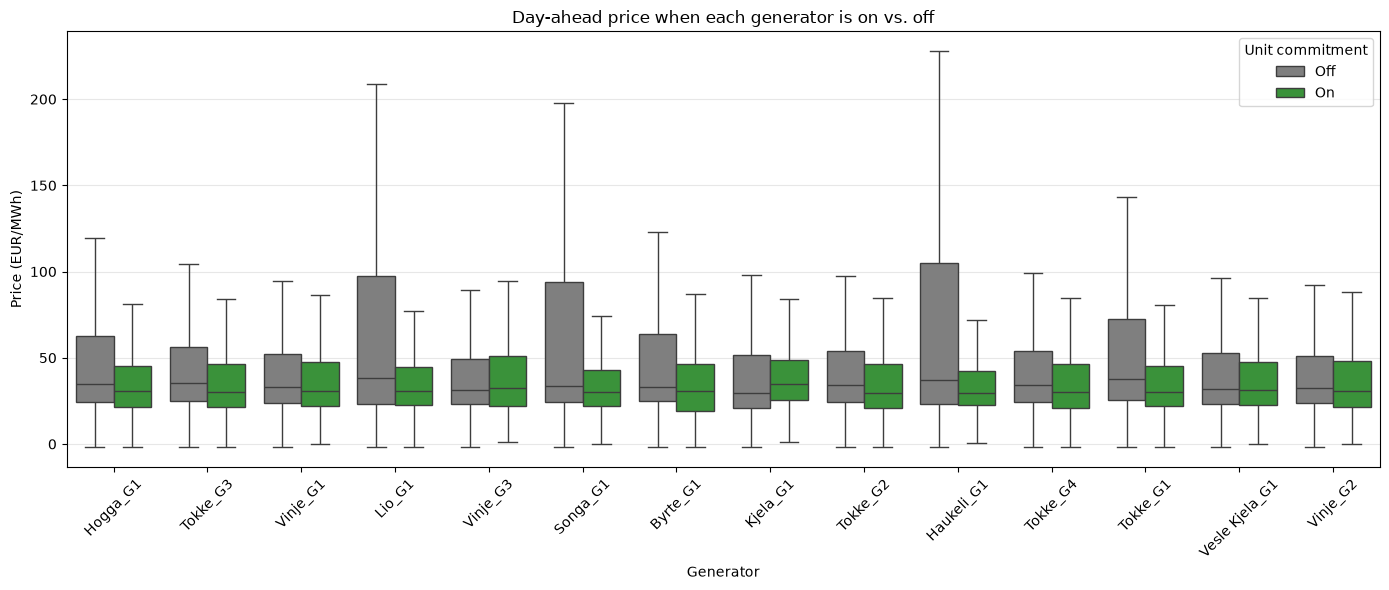

status           Off    On  diff
unit                            
Byrte_G1        33.0  30.8  -2.2
Haukeli_G1      37.3  29.4  -7.9
Hogga_G1        34.8  30.5  -4.3
Kjela_G1        29.4  34.8   5.5
Lio_G1          38.5  30.9  -7.6
Songa_G1        33.6  30.1  -3.5
Tokke_G1        37.9  30.1  -7.8
Tokke_G2        34.4  29.8  -4.6
Tokke_G3        35.4  30.0  -5.5
Tokke_G4        34.3  30.0  -4.2
Vesle Kjela_G1  32.2  31.1  -1.0
Vinje_G1        33.0  30.8  -2.3
Vinje_G2        32.8  30.7  -2.1
Vinje_G3        31.5  32.5   1.0


In [7]:
price = pd.read_csv("sintef_project/data/kernel/Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"], index_col="date")["Day-ahead price (EUR/MWh)"]
price.index = pd.to_datetime(price.index, utc=True).tz_localize(None).floor("h")
price = price[~price.index.duplicated()].rename("price")
uc = pd.read_csv("sintef_project/data/kernel/Unit_commitment_decisions.csv",  parse_dates=["starttime"]).drop(columns=["total_calculation_time"])
long = uc.melt(id_vars=["Run No", "starttime"], var_name="col", value_name="status")
parts = long["col"].str.extract(r"result_committed_(?P<unit>.+)_t(?P<t>\d+)$")
long["unit"] = parts["unit"]
long["t"] = parts["t"].astype(int)
long["time"] = long["starttime"] + pd.to_timedelta(long["t"], unit="h")
long = (long.sort_values("t").drop_duplicates(["unit", "time"], keep="first").drop(columns=["col", "Run No", "starttime"]))
df = long.merge(price, left_on="time", right_index=True, how="inner").dropna(subset=["price"])
df["status"] = df["status"].round().astype(int).map({0: "Off", 1: "On"})
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=df, x="unit", y="price", hue="status", hue_order=["Off", "On"], palette={"Off": "tab:gray", "On": "tab:green"}, showfliers=False, ax=ax)
ax.set_title("Day-ahead price when each generator is on vs. off")
ax.set_xlabel("Generator")
ax.set_ylabel("Price (EUR/MWh)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Unit commitment")
fig.tight_layout()
plt.show()
print(df.groupby(["unit", "status"])["price"].median().unstack().assign(diff=lambda d: d["On"] - d["Off"]).round(1))

The topology file describes the physical structure of the watercourse as a directed graph of 17 reservoirs, 9 power plants with 14 generating units (1003 MW installed in total), 5 tunnels and 37 river segments (bypass, spill and regulated flow). The figure below shows the resulting network, with elevation on the vertical axis and the flow direction running from upstream (left) to downstream (right). It shows that the system is a strongly coupled cascade rather than a set of independent plants. The reservoirs span roughly 1000 m of elevation, from Langesae (HRL 1090 m) down to Bandak (73 m), and almost all water ends up in Bandak, either through the Tokke plant or through the river Vest-Vassdraget. The longest chain starts at Songavatn and passes through Songa, Totak, Vaamarvatn, Vinje, Vinjevatn, Tokke and Bandak before reaching Hogga. This means the discharge of an upstream plant becomes the inflow of the reservoir feeding the next plant, so that the commitment of one unit changes the water available to the units below it. Vinjevatn acts as a hub, receiving the discharge of Vinje and Haukeli and several river flows, and it feeds Tokke, the largest plant (4 x 107.5 MW). Reservoir sizes also differ strongly: Songavatn (640) is by far the largest, followed by Totak, Bordalsvatn and Bandak, while Hyljelihyl (0.26) and Vatjern (0.3) have almost no storage capacity. This agrees with the constant volumes found for these two reservoirs above, and it explains why they behave like pass-through points. The topology also supports the earlier observations that some reservoirs have perfectly correlated inflows and that several water values look alike, since reservoirs directly above or below each other share inflow patterns and probably the same marginal value of water. For feature engineering, this suggests that features of the upstream and downstream neighbours of a unit (such as their volumes, inflows or water values) may be informative in addition to features of the unit's own reservoir.

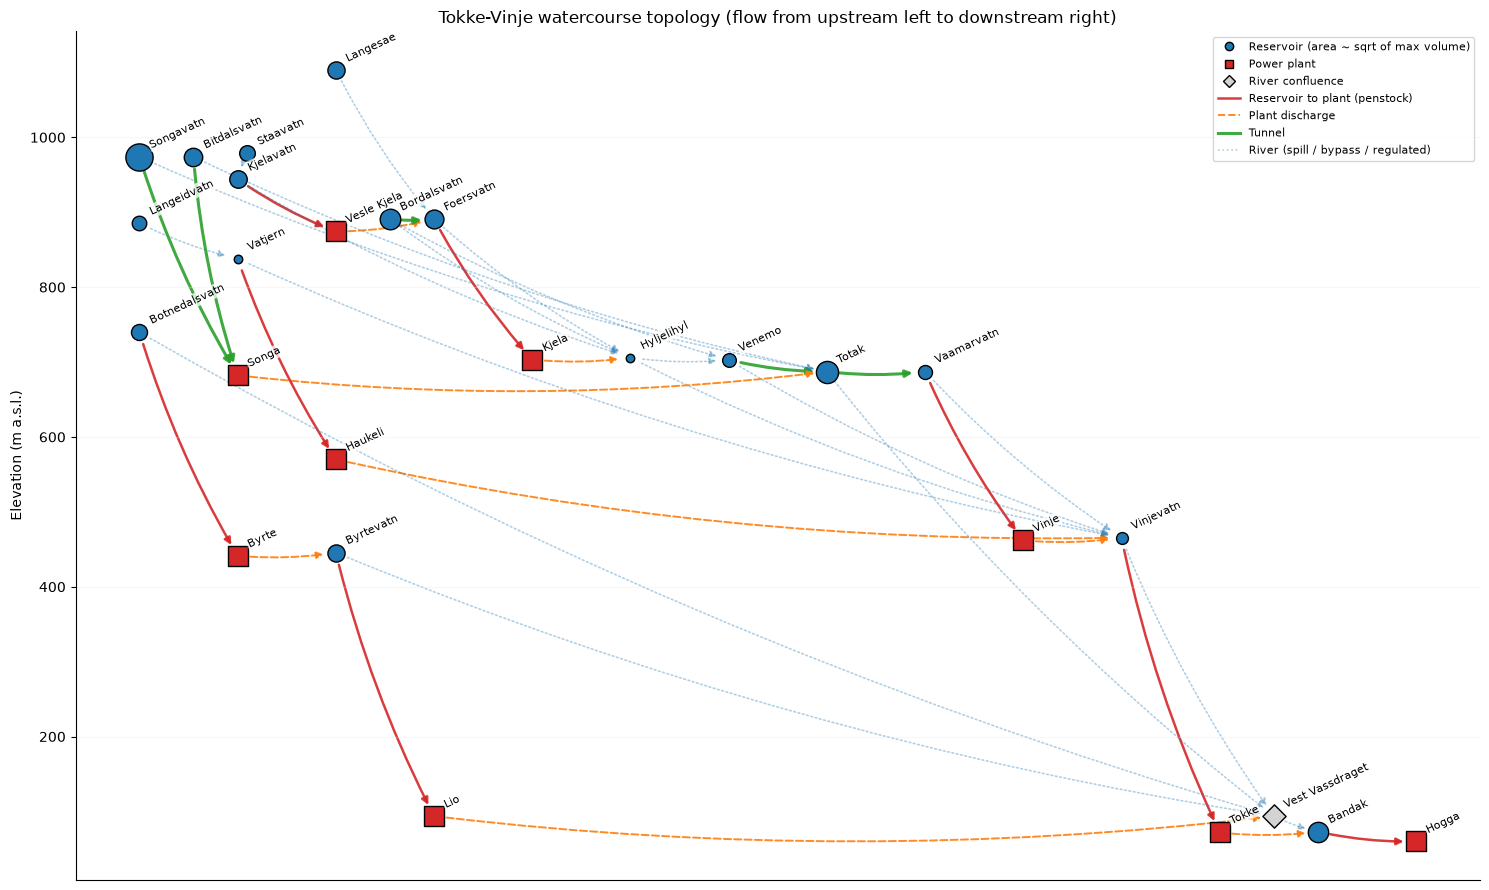

17 reservoirs, 9 plants, 14 generators, 5 tunnels, 37 river segments; installed capacity 1003 MW


In [17]:
import yaml
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

with open("sintef_project/data/extended/Tokke_Vinje_topology.yaml") as f:   # adjust path if needed
    topo = yaml.safe_load(f)
model, conns = topo["model"], topo["connections"]
res, plants, tunnels, rivers, gens = (model[k] for k in ("reservoir", "plant", "tunnel", "river", "generator"))

# Full graph: reservoirs, rivers, tunnels and plants are nodes (generators are attached to their plant)
raw = nx.DiGraph()
raw.add_edges_from((c["from"], c["to"]) for c in conns if "generator" not in (c["from_type"], c["to_type"]))

# Collapse pass-through rivers/tunnels into edges; the confluence river r_Vest_Vassdraget (several inputs) stays a node
keep = lambda n: n in res or n in plants or n == "r_Vest_Vassdraget"
G = nx.DiGraph()
G.add_nodes_from(n for n in raw if keep(n))
for u, v in raw.edges:
    if keep(u) and keep(v):
        G.add_edge(u, v, kind="direct")
for n in raw:
    if not keep(n):
        for u in raw.predecessors(n):
            for v in raw.successors(n):
                if not (G.has_edge(u, v) and G[u][v]["kind"] == "tunnel"):
                    G.add_edge(u, v, kind="tunnel" if n in tunnels else "river")

# Node elevation (m): reservoir HRL, plant outlet line, confluence river elevation
elev = {n: res[n]["hrl"] for n in res}
elev.update({p: plants[p]["outlet_line"] for p in plants})
elev["r_Vest_Vassdraget"] = rivers["r_Vest_Vassdraget"]["upstream_elevation"]

def category(u, v, d):
    if d["kind"] == "tunnel":
        return "Tunnel"
    if v in plants:
        return "Reservoir to plant (penstock)"
    if u in plants:
        return "Plant discharge"
    return "River (spill / bypass / regulated)"

style = {"Reservoir to plant (penstock)": dict(color="tab:red", ls="-", lw=1.8, alpha=0.9),
         "Plant discharge": dict(color="tab:orange", ls="--", lw=1.4, alpha=0.9),
         "Tunnel": dict(color="tab:green", ls="-", lw=2.2, alpha=0.9),
         "River (spill / bypass / regulated)": dict(color="tab:blue", ls=":", lw=1.2, alpha=0.35)}

# Layout: x = depth in the flow network (upstream -> downstream), y = elevation
depth = {n: 0 for n in G}
for n in nx.topological_sort(G):
    for p in G.predecessors(n):
        depth[n] = max(depth[n], depth[p] + 1)
for n in reversed(list(nx.topological_sort(G))):          # pull pure sources towards their targets
    if G.in_degree(n) == 0 and G.out_degree(n) > 0:
        depth[n] = min(depth[s] for s in G.successors(n)) - 1
pos = {}
for L in sorted(set(depth.values())):
    prev, x_off = None, 0
    for n in sorted((n for n in G if depth[n] == L), key=lambda n: elev[n]):
        x_off = x_off + 0.55 if prev is not None and elev[n] - prev < 60 else 0   # separate near-equal elevations
        pos[n] = (L - min(depth.values()) + x_off, elev[n])
        prev = elev[n]

fig, ax = plt.subplots(figsize=(15, 9))
for u, v, d in G.edges(data=True):
    st = style[category(u, v, d)]
    ax.annotate("", xy=pos[v], xytext=pos[u], zorder=1,
                arrowprops=dict(arrowstyle="-|>", shrinkA=9, shrinkB=9, connectionstyle="arc3,rad=0.06",
                                color=st["color"], ls=st["ls"], lw=st["lw"], alpha=st["alpha"]))
for n, (x, y) in pos.items():
    if n in res:
        ax.scatter(x, y, s=30 + 14 * np.sqrt(res[n]["max_vol"]), c="tab:blue", edgecolor="k", zorder=3)
    elif n in plants:
        ax.scatter(x, y, s=220, marker="s", c="tab:red", edgecolor="k", zorder=3)
    else:
        ax.scatter(x, y, s=140, marker="D", c="lightgray", edgecolor="k", zorder=3)
    ax.annotate(n.replace("r_", "").replace("_", " "), (x, y), xytext=(6, 6), textcoords="offset points",
                fontsize=8, rotation=25, zorder=4, bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.75))

handles = [Line2D([], [], marker="o", ls="", mfc="tab:blue", mec="k", label="Reservoir (area ~ sqrt of max volume)"),
           Line2D([], [], marker="s", ls="", mfc="tab:red", mec="k", label="Power plant"),
           Line2D([], [], marker="D", ls="", mfc="lightgray", mec="k", label="River confluence")]
handles += [Line2D([], [], color=s["color"], ls=s["ls"], lw=s["lw"], alpha=s["alpha"], label=k) for k, s in style.items()]
ax.legend(handles=handles, loc="upper right", fontsize=8)
ax.set_xticks([]); ax.set_ylabel("Elevation (m a.s.l.)"); ax.grid(axis="y", alpha=0.3)
ax.set_title("Tokke-Vinje watercourse topology (flow from upstream left to downstream right)")
fig.tight_layout()
plt.show()

print(f"{len(res)} reservoirs, {len(plants)} plants, {len(gens)} generators, {len(tunnels)} tunnels, "
      f"{sum(n.startswith(('b_', 's_', 'r_')) for n in rivers)} river segments; installed capacity {sum(g['p_nom'] for g in gens.values()):.0f} MW")

## Feature Engineering
The EDA showed that the raw variables relate to UC decisions in complex and often indirect ways, meaning the information needed to explain the commitment decisions is not fully captured by the raw columns and needs to be made explicit through feature engineering. Both feature extraction to create new variables from the existing data, for instance by combining, transforming or aggregating columns so that the relationships relevant to the problem become easier for a model to exploit, and feature selection, reducing the resulting feature set to the variables that carry useful information, which limits redundancy, lowers the risk of overfitting and keeps the models interpretable, are used.


#### Baseline model
To start, simple xgboost models were trained on the features exactly as they appear in the data: the day-ahead price, inflow, reservoir volume, water value, minimum volume and minimum flow, aligned to a common time resolution, with the unit commitment status as the target. This model used logistic regression and a shallow decision tree because those are fast, easy to interpret and make few assumptions, so any improvement can be attributed to the features rather than to model complexity. The performance was measured with accuracy and ROC-AUC. This baseline serves two purposes. It gives a reference score that every later feature set must beat to justify its added complexity, and it shows how much of the commitment behaviour is already explained by the raw data.

#### Candidate features from domain logic
Rather than generating features blindly, knowledge of the operation of hydropower producers was used to come up with candidates that reflect the underlying decision problem. A reservoir-based producer does not simply run when the price is high. It compares the current price with the value of storing the water for later, and it is restricted by physical and regulatory limits. This led to the following groups of candidates:

- Economic signals. The difference or ratio between the day-ahead price and the water value is the most direct expression of the producer’s decision     rule: produce when the price exceeds the value of stored water. We also considered the price relative to its recent average, and its rank within the   day or week, to capture whether an hour is cheap or expensive in context.
- Temporal patterns. Hour of day, day of week and month capture the daily load pattern and the seasonal cycle. Lagged and rolling-window versions of     the price (e.g. previous 24 hours, 7-day mean) capture short-term market dynamics.
- Reservoir state and constraints. The headroom above the minimum volume (volume − min_volume), the volume as a fraction of its historical range, and    the change in volume over recent days describe how much flexibility a unit has. Likewise, inflow minus minimum flow indicates whether the flow         constraint is binding. Cumulative or lagged inflow reflects the delayed response of reservoirs to snowmelt and rain.
- System and plant interactions. Generators in the same cascade or power station tend to be operated together, and due to the connectedness of the       system, reservoirs and plants that are upstream/downstream from each other can significantly influence outcome decisions.

Throughout the candidate generation and filtering, relative features (differences, ratios, ranks and normalised values) were favoured over the raw absolute values for several reasons: They are robust to changes over time, as price levels shifted considerably over the period 2015-2026, so a threshold learned from absolute prices in the training years may not hold in the test years. They are comparable across units, which is crucial because reservoirs differ greatly in size, and plants differ in capacity, so a volume of a given size means very different things for different units. And they match the decision logic: A producer does not compare the price to a fixed number but to the value of the stored water

#### Candidate filtering
This candidate set is large and contains many overlapping features, so before running expensive cross-validated model comparisons a quick univariate filter was applied. It was computed separately for each unit, since the same feature can matter for one generator and not for another. The purpose of the filter is to prune clearly useless features cheaply. It is not meant to produce the final feature set, because it scores each feature in isolation and therefore misses interactions between features. Each feature was scored against the on/off target with up to three measures:

- Spearman correlation. This rank-based correlation is robust to outliers (price spikes are common in this data) and detects any monotonic               relationship, not only linear ones.
- Single-feature AUC, scored as |AUC − 0.5|. The ROC-AUC was computed when using the feature alone as a classifier score, and its distance from 0.5 (random guessing) was measured. Taking the absolute value makes the score direction-agnostic, so features that predict “off” as strongly as “on” are not penalised. AUC is considered the most important score as it is also the metric on which the final models are evaluated.
- Mutual information. Mutual information captures non-monotonic relationships that correlation misses. Hour of day is a typical example: a unit may be   on during the day and in the evening but off at night, so the Spearman correlation is close to zero even though the feature is highly informative.

To check that a feature’s effect is reliable rather than the result of one unusual period, a sign consistency score was also computed (the share of years in which the feature’s effect on the target has the same sign). These scores were then interpreted using three principles rather than a fixed cut-off: A feature with a small effect that has the same sign in every year is more trustworthy than a strong effect that appears in one year only and reverses in others. Only features with near-zero strength in every unit and no domain reason to matter were removed. The filter was deliberately lenient, because a feature can score low on its own and still help through interactions. Categorical or cyclical features were not judged by correlation, as hour of day and month look weak under Spearman because their relationship with the target is not monotonic (and they did also score poorly on AUC as expected), but rather by mutual information.

#### Final feature selection
The final feature set was chosen differently: feature groups were repeatedly added, removed or reformulated, to train increasingly complex models on each version, while keeping changes that improved validation performance. This was trial and error, but guided by the domain logic from the second step. The result is a single feature set, called variant L, which feeds both final models. They differ in the learners built on top of it. The final features fall into three groups, all computed per plant.

Relative market and state features. Following the argument for relative over absolute features, almost all price features are expressed relative to a reference level (although absolute values such as reservoir volume and inflow were kept as well, because relative features discard level information):

- Price shape: the log of the price divided by the weekly mean, the same quantity one hour earlier and later, the rank of the price within the day and   within the week, and standardised deviations from the daily and weekly mean.
- Price versus water value: the log of the price divided by the water value at the start and end of the week, for each reservoir the plant uses. This    is the direct implementation of the producer’s decision rule.
- Reservoir state and constraints: the fill level, the volume above the minimum volume, the downstream shortfall and the head, rather than raw volumes   alone.
- Spill pressure: cumulative inflow divided by capacity, and the volume plus cumulative inflow minus maximum volume, divided by capacity. This           captures how close a reservoir is to spilling, which forces the plant to run regardless of price.
- Calendar and season: hour of week, hour of day, day of week and day of year. The cyclical features were kept because they carry information that       correlation filters underrate.

Before any model was trained, we checked how informative three scores are when used alone against the unit commitment (Table 1). The price rank within the week, which only says which hours are the cheapest or most expensive, has a micro AUC of 0.589. The log of the price divided by the water value reaches 0.872. Comparing the price with the value of the stored water therefore carries far more information about the commitment than the price pattern alone.

**Table 1.** Micro AUC of single scores used alone against the unit commitment (all cases, 2015-2022).

| Score used alone | Micro AUC |
|---|---|
| Price rank within the week | 0.589 |
| log(price / water value) | 0.872 |
| Optimizer surrogate (estimated running units) | 0.777 |

Optimizer-based features. The most distinctive step was to turn small optimization problems into features, so that the learners receive an approximation of the scheduling decision instead of having to discover it from raw columns. The reasoning is that price features tell a model which hours are the best, but not how many hours a plant will run in a week, which depends on the available water, the turbine capacity and the water value. An error analysis of the model without surrogates showed that most of the remaining error was at this weekly level. None of these features uses the labels: they are built only from inputs known at the start of the week, and the labels serve only to evaluate them.

- Optimizer surrogate: a fast approximation of the scheduling decision for one plant. The weekly water budget is estimated from the hours in which the   price exceeds the water value, limited by the water available and the turbine capacity, and then poured into the highest-priced hours until it is      used up. The result is an hourly dispatch profile, computed for four budgets (the minimum to avoid spill, the water value at the start of the week,    the water value at the end, and the maximum usable). For a typical week, the surrogate therefore switches units on in the hours where the price is     well above the water value and leaves them off in the cheap hours, which is the pattern a producer following the decision rule would show. The         resulting budget follows the real share of running hours per week, which the price rank cannot do because its weekly mean is the same in every week.   Across non-overlapping weeks, the correlation between the budget and the real share of ON hours is high for Vesle Kjela (r = 0.97), Songa (0.95) and   Byrte (0.99), and still good for Kjela (0.91) and Hogga (0.88). It is weaker for Lio (0.70), Haukeli (0.62), Vinje (0.50) and Tokke (0.44), where      the water coming from upstream is harder to approximate.
- Viterbi on/off margins: a two-state forward-backward pass computes, for each unit and hour, the best weekly value with the unit on minus the best      value with it off, including start and stop costs. Commitment decisions are persistent and starts cost money, so a unit does not switch on for a       single cheap hour. The margins encode this without using the target. They are computed for three price definitions, namely price minus water value     and two versions scaled by the unit’s marginal power ratio.
- Cascade linear program (LP): the surrogate looks at one plant at a time and only approximates the water coming from upstream, and its budget often     saturates at 0 or 1. One weekly LP over all reservoirs, rivers, tunnels and generators removes this limit and gives the relative flow and the          reduced cost divided by the water value for each unit. It has no on/off variables and no start/stop costs, so these features are soft signals rather   than exact answers. On the same weeks, the LP reduced cost alone reaches a micro AUC of 0.900, against 0.774 for the surrogate. The improvement is     largest where the surrogate was weakest: for Tokke, the correlation of the weekly LP flow with the real share of running hours is 0.86, against 0.44   for the surrogate budget.

Cascade features. Since plants share water, a plant’s decisions depend on those upstream of it. For the tree branches, the predicted commitment of upstream plants (mean probability, lagged by 1 and 3 hours, and weekly mean) and the expected upstream release become features of the downstream plant. Predictions are generated out-of-fold, so no information leaks from the targets into the training features. The TCN does not need these features because it sees all plants at once.

Table 2 shows the main steps of the trial-and-error process. Not every step produced a measurable gain. Differences between runs of the same model are about 0.0015 micro AUC, so the last two steps (per-unit physics and the LP) are within the run-to-run variation on the test set. The clearest gains come from the surrogate and from the constraint-corrected surrogate. Only the step from C to S isolates one change; the later steps also changed other things, such as the use of unscaled prices and water values and a topology fix for Haukeli, so their gains cannot be attributed to a single feature group. The gains are also not uniform across units: the surrogate improved Tokke (+0.038 on the test set), Lio (+0.034) and Hogga (+0.020), but made Songa worse (−0.026).

**Table 2.** Micro AUC of the feature variants, trained on the first 80% of the cases and tested after a 7-day gap.

| Variant | Content | OOF | Test |
|---|---|---|---|
| C | Base: price, inflow, volumes, water values, stacking | 0.9612 | 0.9438 |
| S | C + surrogate dispatch | 0.9716 | 0.9570 |
| K | S + surrogate corrected by min flow / min volume, constraint features | 0.9754 | 0.9715 |
| N | K + unscaled prices and water values, Haukeli topology fix | 0.9780 | 0.9806 |
| P | N + per-unit physics and start/stop costs | 0.9788 | 0.9823 |
| L | P + LP of the cascade | 0.9811 | 0.9825 |

Two things stand out. First, the engineered features did what the exploratory analysis suggested. The raw price was a weak predictor of commitment, but the combination of price, water value and reservoir state, summarised by the surrogate and Viterbi features, supports micro AUCs of about 0.983 for the tree branches on the local test set. Second, the benefit differs by unit. Units in the lower cascade and the large Tokke and Vinje stations score around 0.98 to 0.99, while Haukeli (about 0.92) and Lio (about 0.94) remain hardest. Both depend on reservoirs whose water values come from neighbouring reservoirs in our mapping, so the water-value features are probably the least precise for them. This is a plausible explanation rather than something we tested directly, although the topology fix and the LP both mainly improved Haukeli (the LP raised its test AUC from 0.898 to 0.923).

## Model Selection
Which models did we consider, how did we test them, which model did we finally choose and why

## Final Models

## Model Interpretation

# DONT FORGET

"Please use clear section titles in the report for easy lookup of the above parts"

"You must describe how you obtain the values of the hyperparameters in the report."

"No model interpretation (-3). To avoid the deduction, you should show one or more model interpretation results (e.g., PDP, feature importance, LIME, and SHAP) in the report"

Change the title in the beginning!